# EDA : diagnóstico pós-tratamento

In [7]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

In [8]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from src.analysis import diagnostics as D
meta = D.check_alignment(); imgs = D.load_stage_images()
feats = pd.read_csv('reports/eda_1/tidy_manifest_eda.csv')
e1 = D.per_sample_errors(Path('multirun/cnn_test1'), meta, range(10))
e2 = D.per_sample_errors(Path('multirun/cnn_test2'), meta, range(10))

## Malignas sempre erradas

In [9]:
a1, a2 = D.always_wrong_malignant(e1), D.always_wrong_malignant(e2)
pd.DataFrame({d: {'cruas': len(a1[d]), 'tratadas': len(a2[d]), 'em ambas': len(a1[d] & a2[d])} for d in D.DOMAINS})

,small,medium,big
cruas,7,13,5
tratadas,5,8,7
em ambas,4,7,3


## Correlação (Spearman) erro vs SNR/speckle, malignas in-domain

In [10]:
pd.concat({'cruas': D.error_feature_corr(e1, feats), 'tratadas': D.error_feature_corr(e2, feats)}, axis=1).round(2)

cruas              tratadas             
                 small medium   big    small medium   big
snr_db            0.42  -0.01  0.32     0.42  -0.03  0.23
speckle_index    -0.31   0.21 -0.29    -0.29   0.38 -0.24
roi_mean          0.22   0.28  0.32     0.21   0.08  0.23
roi_std          -0.25   0.30 -0.09    -0.23   0.06 -0.03
roi_entropy_bits  0.07   0.33  0.33     0.07   0.13  0.21

In [11]:
pd.DataFrame({k: D.domain_identifiability(v, meta) for k, v in imgs.items()}).T.round(3)

,pixels_pca,intensity_stats_only
raw64,0.652,0.641
crop64,0.551,0.603
final,0.548,0.357


## 4. Inspeção visual

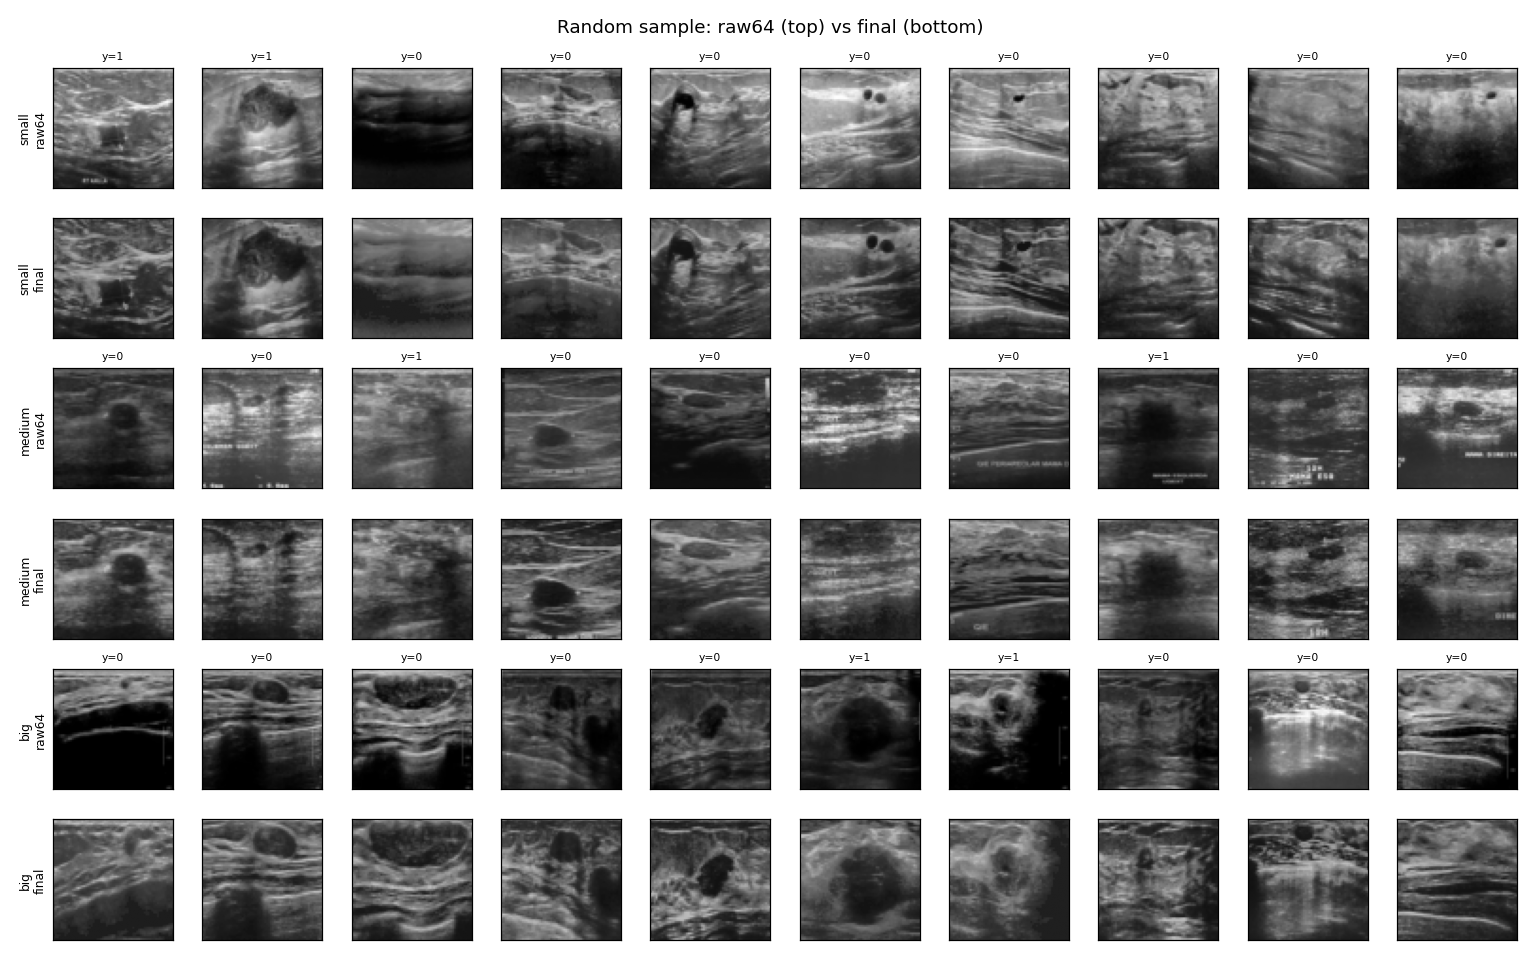

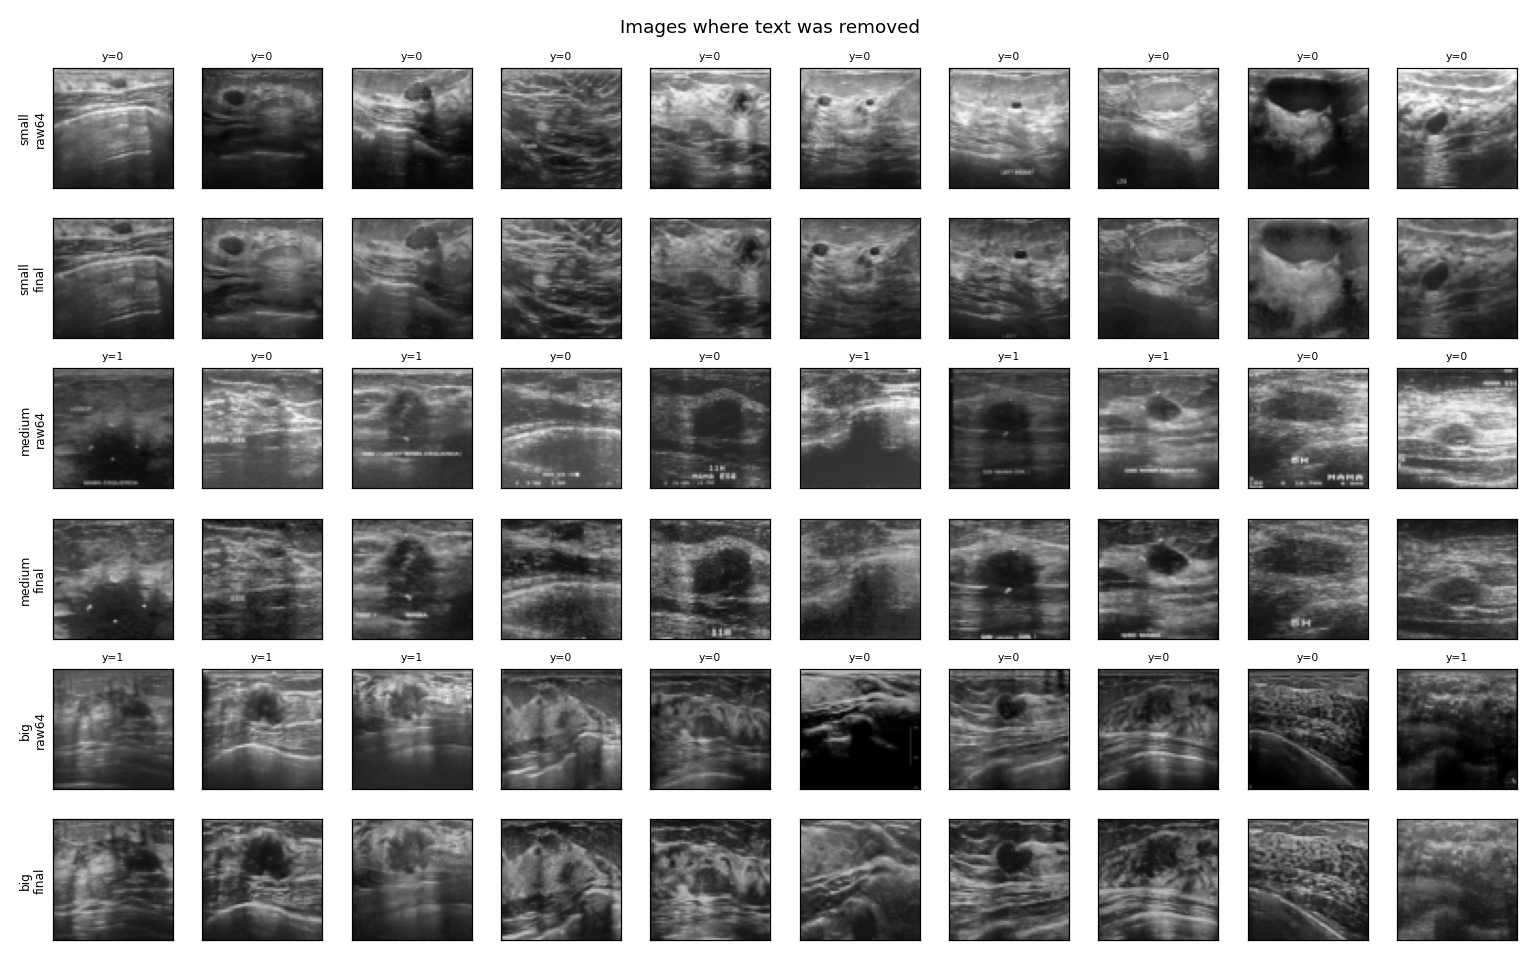

In [12]:
display(Image('reports/eda_3/grid_random.png')); display(Image('reports/eda_3/grid_text_removed.png'))